# Практическое занятие №10 — самостоятельная часть

**Дисциплина:** «Алгоритмы машинного обучения для решения прикладных задач»  
**Вуз:** МИРЭА — Российский технологический университет, семестр 1  
**Преподаватель:** доцент Осипов А. В.

**Замечание о материале занятия.** На титульном листе PDF указана тема «кластеризация DBSCAN, агломеративная кластеризация». Само содержимое слайдов — это разбор полносвязной нейронной сети (персептрон) в PyTorch на примере MNIST (ноутбук `s5.ipynb` / «Текущий контроль 5»). Самостоятельное задание в конце слайдов относится именно к нейронной сети, поэтому ниже выполняется оно, в том же стиле, что и аудиторная часть.

Датасет берётся из архива «Текущий контроль 3-4» (это тот же `winequality-red.csv`, что использовался в практической части занятия №3-4). Файл лежит рядом с ноутбуком.


## Формулировка задания

> С помощью нейронной сети классифицировать вина по качеству. Датасет взять из третьей работы. Разбить датасет на два класса по качеству вина. Качество вина **до пяти включительно** определить как первый класс, **свыше пяти** — как второй. Представить основные показатели метода. Сравнить результат классификации с результатом из третьей работы.

В третьей работе (практическое занятие №3-4) та же таблица классифицировалась **логистической регрессией**, но порог был другим: «хорошее» вино — это качество **7 и выше**. Метрики третьей работы на тестовой выборке (25 %, `random_state=0`, `class_weight='balanced'`):

| | precision | recall | f1-score | support |
|---|---:|---:|---:|---:|
| Не качественное | 0.93 | 0.78 | 0.85 | 346 |
| Хорошее | 0.32 | 0.65 | 0.42 | 54 |
| **accuracy** |  |  | **0.7625** | 400 |

Чтобы сравнение было честным, ниже будет два среза:

1. нейронная сеть и логистическая регрессия **на одной и той же разметке задания** (качество ≤ 5 / > 5) и на одном разбиении;
2. нейронная сеть на **разметке третьей работы** (качество ≥ 7), чтобы сравнить методы при одинаковой постановке.


## 1. Импорт библиотек

Используются те же пакеты, что и в аудиторной части: `torch` / `torch.nn` / `Adam` для сети, `classification_report` для метрик, `matplotlib` для графиков. Дополнительно нужны `pandas` (чтение CSV), `StandardScaler` и `train_test_split`.


In [1]:
# Фиксируем зерно сразу, чтобы разбиение выборки и инициализация весов
# воспроизводились от запуска к запуску.
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay,
)

# Подписи осей на русском; DejaVu Sans содержит кириллицу.
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Как в аудиторной работе: берём GPU, только если он реально доступен.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cpu


## 2. Загрузка датасета из третьей работы

Файл `winequality-red.csv` — выборка *Wine Quality* (красное вино, UCI): 11 физико-химических признаков и целочисленная оценка `quality` от 3 до 8. Путь относительный: файл лежит в той же папке, что и ноутбук.


In [2]:
# sep по умолчанию — запятая; в архиве именно такой CSV (не «точка с запятой» с UCI).
wine = pd.read_csv("winequality-red.csv")

print("Размер выборки:", wine.shape)
print("Признаки:", list(wine.columns[:-1]))
print("Пропусков:", int(wine.isna().sum().sum()))
print("\nРаспределение исходной оценки quality:")
print(wine["quality"].value_counts().sort_index())
wine.head()


Размер выборки: (1599, 12)
Признаки: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Пропусков: 0

Распределение исходной оценки quality:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Разметка двух классов по условию задания

- **класс 0 (первый)** — качество вина до пяти включительно: `quality <= 5`;
- **класс 1 (второй)** — качество свыше пяти: `quality > 5`.

Это другая задача, чем в третьей работе: там «хорошим» считалось только вино с оценкой 7+, и класс был редким (217 из 1599). Здесь граница проходит между типичными оценками 5 и 6, классы почти сбалансированы.


In [3]:
# Целевой столбец по формулировке задания. int: так удобнее и sklearn, и CrossEntropyLoss.
wine["class"] = (wine["quality"] > 5).astype(int)

class_names = ["качество ≤ 5", "качество > 5"]

print("Распределение классов задания:")
print(wine["class"].value_counts().sort_index().rename({0: class_names[0], 1: class_names[1]}))
print("Доля класса 1 (качество > 5): {:.3f}".format(wine["class"].mean()))

# Матрица объектов — только физико-химические признаки, без quality и без метки.
feature_names = [c for c in wine.columns if c not in ("quality", "class")]
X = wine[feature_names].values.astype(np.float32)
y = wine["class"].values.astype(np.int64)
print("X:", X.shape, "y:", y.shape)


Распределение классов задания:
class
качество ≤ 5    744
качество > 5    855
Name: count, dtype: int64
Доля класса 1 (качество > 5): 0.535
X: (1599, 11) y: (1599,)


## 4. Обучающая и тестовая выборки, масштабирование

Признаки имеют разный масштаб (`density` около 1, `total sulfur dioxide` — десятки). Для градиентного спуска в нейросети это важно: без стандартизации шаги по разным координатам будут несоизмеримы. Масштаб оцениваем **только на обучении**, иначе в тест «утечёт» информация о распределении.


In [4]:
# test_size=0.25 и random_state=0 — как в третьей работе, чтобы сравнение было прозрачным.
# stratify сохраняет долю классов в обеих частях.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Обучение:", X_train_s.shape, "тест:", X_test_s.shape)
print("Классы на обучении:", np.bincount(y_train), "на тесте:", np.bincount(y_test))

# TensorDataset + DataLoader — тот же способ подачи данных, что в аудиторном цикле trainer.
train_ds = TensorDataset(
    torch.tensor(X_train_s, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long),
)
test_ds = TensorDataset(
    torch.tensor(X_test_s, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.long),
)
# Генератор фиксирует порядок перемешивания батчей.
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, generator=g)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)


Обучение: (1199, 11) тест: (400, 11)
Классы на обучении: [558 641] на тесте: [186 214]


## 5. Класс персептрона — как в аудиторной части

Архитектура та же: последовательность блоков `Linear → ReLU → Dropout`, затем линейный классификатор. Отличие только в размерностях: на MNIST было `input_dim=784`, `output_dim=10`, здесь 11 признаков и 2 класса. `num_layers=0` даёт чисто линейный классификатор (по сути, близкий к логистической регрессии).


In [5]:
class Perceptron(nn.Module):
    # Полносвязная сеть из аудиторной работы, приспособленная к табличным признакам.

    def __init__(
        self,
        input_dim=11,
        hidden_dim=64,
        output_dim=2,
        num_layers=2,
        p=0.0,
        device="cpu",
    ):
        super().__init__()
        # Sequential удобно печатать: сразу видно порядок слоёв.
        self.layers = nn.Sequential()
        prev_size = input_dim
        for i in range(num_layers):
            self.layers.add_module("layer{}".format(i), nn.Linear(prev_size, hidden_dim))
            self.layers.add_module("relu{}".format(i), nn.ReLU())
            # В разборе MNIST стояло p=0.0, то есть Dropout фактически выключен.
            self.layers.add_module("dropout{}".format(i), nn.Dropout(p=p))
            prev_size = hidden_dim
        # Последний слой всегда переводит скрытое представление в число классов.
        self.layers.add_module("classifier", nn.Linear(prev_size, output_dim))
        self.to(device)

    def forward(self, input):
        return self.layers(input)


def testing(model, loader):
    # Как процедура testing в занятии: обход датасета, accuracy и classification_report.
    model.eval()
    pred, real = [], []
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            # argmax по последней оси — номер класса с наибольшим логитом.
            pred.extend(torch.argmax(model(x_batch), dim=-1).cpu().numpy().tolist())
            real.extend(y_batch.cpu().numpy().tolist())
    acc = float(np.mean(np.array(real) == np.array(pred)))
    report = classification_report(
        real, pred, target_names=class_names, digits=4, zero_division=0
    )
    return acc, report, np.array(real), np.array(pred)


def trainer(model, loader, loss_function, optimizer, epochs):
    # Цикл обучения как в занятии: по эпохам, внутри — батчи, zero_grad / backward / step.
    history = []
    for epoch in range(epochs):
        model.train()
        running = 0.0
        seen = 0
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            output = model(x_batch)
            loss = loss_function(output, y_batch)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(y_batch)
            seen += len(y_batch)
        history.append(running / seen)
        # Печатаем не каждую эпоху, чтобы не забить вывод.
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print("эпоха {:3d}/{:d}, средняя ошибка CrossEntropy: {:.4f}".format(
                epoch + 1, epochs, history[-1]
            ))
    return history


## 6. Модель до обучения

В аудиторной части сначала смотрели качество необученного классификатора (на MNIST accuracy была около 0.12 — чуть выше случайного 0.10). Здесь случайный бинарный классификатор дал бы примерно 0.5; это нижняя точка отсчёта.


In [6]:
# Два скрытых слоя по 64 нейрона — небольшой запас нелинейности на 11 признаков.
model = Perceptron(
    input_dim=X_train_s.shape[1],
    hidden_dim=64,
    output_dim=2,
    num_layers=2,
    p=0.0,
    device=device,
)
print(model)

acc_before, report_before, _, _ = testing(model, test_loader)
print("\nКачество до обучения, accuracy = {:.4f}".format(acc_before))
print(report_before)


Perceptron(
  (layers): Sequential(
    (layer0): Linear(in_features=11, out_features=64, bias=True)
    (relu0): ReLU()
    (dropout0): Dropout(p=0.0, inplace=False)
    (layer1): Linear(in_features=64, out_features=64, bias=True)
    (relu1): ReLU()
    (dropout1): Dropout(p=0.0, inplace=False)
    (classifier): Linear(in_features=64, out_features=2, bias=True)
  )
)

Качество до обучения, accuracy = 0.4125
              precision    recall  f1-score   support

качество ≤ 5     0.3616    0.3441    0.3526       186
качество > 5     0.4529    0.4720    0.4622       214

    accuracy                         0.4125       400
   macro avg     0.4072    0.4080    0.4074       400
weighted avg     0.4104    0.4125    0.4113       400



## 7. Обучение сети

Функция потерь — `CrossEntropyLoss` (она же использовалась на MNIST): внутри уже есть `log_softmax`, на вход подаются сырые логиты. Оптимизатор — `Adam` с `lr=0.001`. Эпох больше, чем в примере с MNIST (там одна эпоха уже пробегала сотни батчей), потому что выборка вина маленькая: при `batch_size=64` в эпохе всего около 19 шагов.


эпоха   1/80, средняя ошибка CrossEntropy: 0.6670
эпоха  10/80, средняя ошибка CrossEntropy: 0.4732


эпоха  20/80, средняя ошибка CrossEntropy: 0.4396
эпоха  30/80, средняя ошибка CrossEntropy: 0.4118


эпоха  40/80, средняя ошибка CrossEntropy: 0.3831
эпоха  50/80, средняя ошибка CrossEntropy: 0.3548


эпоха  60/80, средняя ошибка CrossEntropy: 0.3233
эпоха  70/80, средняя ошибка CrossEntropy: 0.2920


эпоха  80/80, средняя ошибка CrossEntropy: 0.2671


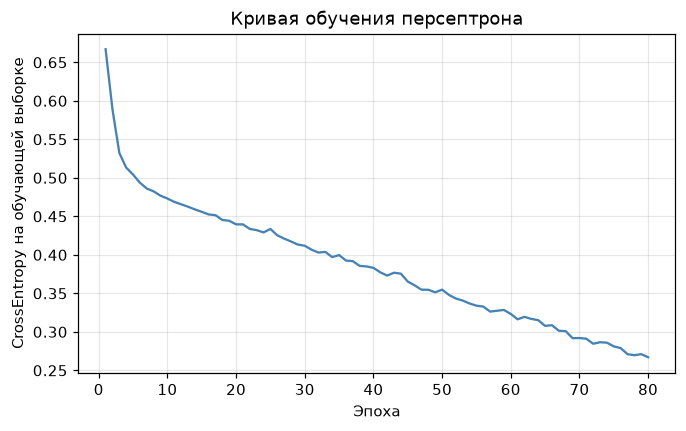

In [7]:
EPOCHS = 80
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss()

history = trainer(model, train_loader, loss_function, optimizer, epochs=EPOCHS)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(history) + 1), history, color="steelblue")
ax.set_xlabel("Эпоха")
ax.set_ylabel("CrossEntropy на обучающей выборке")
ax.set_title("Кривая обучения персептрона")
ax.grid(True, alpha=0.3)
plt.show()


## 8. Основные показатели метода после обучения


Качество после обучения, accuracy = 0.7450
              precision    recall  f1-score   support

качество ≤ 5     0.7165    0.7473    0.7316       186
качество > 5     0.7718    0.7430    0.7571       214

    accuracy                         0.7450       400
   macro avg     0.7442    0.7452    0.7444       400
weighted avg     0.7461    0.7450    0.7453       400

Матрица ошибок (строки — истина, столбцы — прогноз):
[[139  47]
 [ 55 159]]


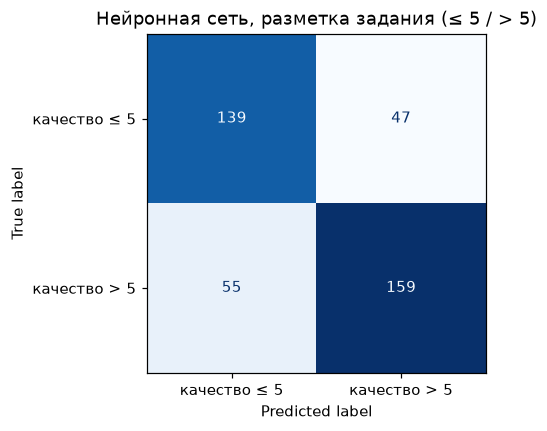

In [8]:
acc_nn, report_nn, y_true, y_pred_nn = testing(model, test_loader)
print("Качество после обучения, accuracy = {:.4f}".format(acc_nn))
print(report_nn)
print("Матрица ошибок (строки — истина, столбцы — прогноз):")
cm_nn = confusion_matrix(y_true, y_pred_nn)
print(cm_nn)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_nn, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Нейронная сеть, разметка задания (≤ 5 / > 5)")
plt.show()


## 9. Сравнение с третьей работой

Сначала обучим логистическую регрессию **на той же разметке и том же разбиении**, что и сеть. Затем повторим постановку третьей работы (порог 7+, `class_weight='balanced'`, без стандартизации — как в том ноутбуке) и прогоним на ней и регрессию, и сеть.


In [9]:
# --- 9.1. Логистическая регрессия на разметке задания (качество ≤ 5 / > 5) ---
logreg_task = LogisticRegression(max_iter=5000, random_state=SEED)
logreg_task.fit(X_train_s, y_train)
y_pred_lr = logreg_task.predict(X_test_s)

print("Логистическая регрессия, разметка задания, accuracy = {:.4f}".format(
    accuracy_score(y_test, y_pred_lr)
))
print(classification_report(y_test, y_pred_lr, target_names=class_names, digits=4))

# --- 9.2. Постановка третьей работы: хорошее вино — quality >= 7 ---
y7 = (wine["quality"] >= 7).astype(np.int64).values
X_train7, X_test7, y_train7, y_test7 = train_test_split(
    X, y7, test_size=0.25, random_state=SEED, stratify=y7
)
# В третьей работе признаки не стандартизовались и ставился class_weight='balanced',
# потому что «хороших» вин мало (около 13.5 %).
logreg7 = LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED)
logreg7.fit(X_train7, y_train7)
y_pred_lr7 = logreg7.predict(X_test7)

names7 = ["Не качественное", "Хорошее"]
print("\nЛогистическая регрессия, постановка 3-й работы (quality >= 7), accuracy = {:.4f}".format(
    accuracy_score(y_test7, y_pred_lr7)
))
print(classification_report(y_test7, y_pred_lr7, target_names=names7, digits=4))
print("Матрица ошибок:")
print(confusion_matrix(y_test7, y_pred_lr7))

# Для сети признаки всё же масштабируем: иначе Adam с lr=0.001 будет сходиться плохо.
scaler7 = StandardScaler()
X_train7_s = scaler7.fit_transform(X_train7)
X_test7_s = scaler7.transform(X_test7)

train7 = DataLoader(
    TensorDataset(
        torch.tensor(X_train7_s, dtype=torch.float32),
        torch.tensor(y_train7, dtype=torch.long),
    ),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
test7 = DataLoader(
    TensorDataset(
        torch.tensor(X_test7_s, dtype=torch.float32),
        torch.tensor(y_test7, dtype=torch.long),
    ),
    batch_size=64,
    shuffle=False,
)

# Сохраняем исходные подписи, временно подставляем подписи третьей работы в testing().
_saved_names = class_names
class_names = names7
model7 = Perceptron(input_dim=11, hidden_dim=64, output_dim=2, num_layers=2, p=0.0, device=device)
_ = trainer(model7, train7, nn.CrossEntropyLoss(), optim.Adam(model7.parameters(), lr=0.001), epochs=EPOCHS)
acc_nn7, report_nn7, y_true7, y_pred_nn7 = testing(model7, test7)
class_names = _saved_names

print("\nНейронная сеть, постановка 3-й работы (quality >= 7), accuracy = {:.4f}".format(acc_nn7))
print(report_nn7)
print("Матрица ошибок:")
print(confusion_matrix(y_true7, y_pred_nn7))


Логистическая регрессия, разметка задания, accuracy = 0.7600
              precision    recall  f1-score   support

качество ≤ 5     0.7368    0.7527    0.7447       186
качество > 5     0.7810    0.7664    0.7736       214

    accuracy                         0.7600       400
   macro avg     0.7589    0.7595    0.7591       400
weighted avg     0.7604    0.7600    0.7601       400


Логистическая регрессия, постановка 3-й работы (quality >= 7), accuracy = 0.7600
                 precision    recall  f1-score   support

Не качественное     0.9340    0.7775    0.8486       346
        Хорошее     0.3125    0.6481    0.4217        54

       accuracy                         0.7600       400
      macro avg     0.6233    0.7128    0.6351       400
   weighted avg     0.8501    0.7600    0.7909       400

Матрица ошибок:
[[269  77]
 [ 19  35]]


эпоха   1/80, средняя ошибка CrossEntropy: 0.4953
эпоха  10/80, средняя ошибка CrossEntropy: 0.2420


эпоха  20/80, средняя ошибка CrossEntropy: 0.2167
эпоха  30/80, средняя ошибка CrossEntropy: 0.1961


эпоха  40/80, средняя ошибка CrossEntropy: 0.1725
эпоха  50/80, средняя ошибка CrossEntropy: 0.1467


эпоха  60/80, средняя ошибка CrossEntropy: 0.1259
эпоха  70/80, средняя ошибка CrossEntropy: 0.1087


эпоха  80/80, средняя ошибка CrossEntropy: 0.0869

Нейронная сеть, постановка 3-й работы (quality >= 7), accuracy = 0.8925
                 precision    recall  f1-score   support

Не качественное     0.9366    0.9393    0.9380       346
        Хорошее     0.6038    0.5926    0.5981        54

       accuracy                         0.8925       400
      macro avg     0.7702    0.7659    0.7680       400
   weighted avg     0.8917    0.8925    0.8921       400

Матрица ошибок:
[[325  21]
 [ 22  32]]


## Выводы

1. По заданию самостоятельного занятия вина делятся на два почти равных класса: качество ≤ 5 (744 объекта) и качество > 5 (855 объектов). Это существенно отличается от третьей работы, где «хорошим» считалось только вино с оценкой 7+ (217 объектов из 1599), и метрики там в первую очередь описывали редкий положительный класс.

2. Полносвязная сеть с двумя скрытыми слоями (64 нейрона, ReLU, Adam, 80 эпох, `CrossEntropyLoss`) на тестовых 400 объектах даёт **accuracy 0.7450** и макро-F1 **0.7444**. До обучения accuracy была 0.4125 (хуже случайного угадывания). После обучения классы распознаются почти одинаково: для качества ≤ 5 precision 0.7165, recall 0.7473, F1 0.7316; для качества > 5 — 0.7718, 0.7430 и 0.7571. Матрица ошибок: 139 и 159 верных ответов, 47 и 55 ошибок.

3. Логистическая регрессия на **той же** разметке и **том же** разбиении получает **accuracy 0.7600** и макро-F1 **0.7591** — на полтора процентных пункта выше, чем сеть. Для этой таблицы линейной разделяющей поверхности уже достаточно: нелинейные слои персептрона выигрыша не дают.

4. Если повторить постановку третьей работы (порог 7+), логистическая регрессия воспроизводит её результат: accuracy **0.7600** (в исходном ноутбуке №3-4 было 0.7625, расхождение в пределах одной-двух ошибок на 400 объектах), F1 класса «Хорошее» **0.4217**, полнота 0.6481 при точности 0.3125. Сеть в этой постановке даёт более высокую accuracy **0.8925**, но это в основном за счёт большинства «некачественных» вин (F1 0.9380). У редкого класса «Хорошее» F1 сети **0.5981** выше, чем у регрессии (0.4217), при этом полнота чуть ниже (0.5926 против 0.6481), а точность выше (0.6038 против 0.3125). Сравнивать методы только по accuracy здесь нельзя.

5. Итог: на разметке текущего задания нейронная сеть работает примерно так же, чуть хуже логистической регрессии (0.745 против 0.760). Большая часть видимой разницы с цифрами третьей работы объясняется не моделью, а другим порогом по `quality`.
